# The hidden reason Olist customers leave 1★ reviews: split shipments
### *From Lead to Loyal*: an end-to-end analysis of a Brazilian marketplace's seller funnel, deliveries and reviews
**Amelie Pham** · MS Management & Analytics, NYU SPS · SQL · Python · NLP · LLM · Machine learning · A/B testing

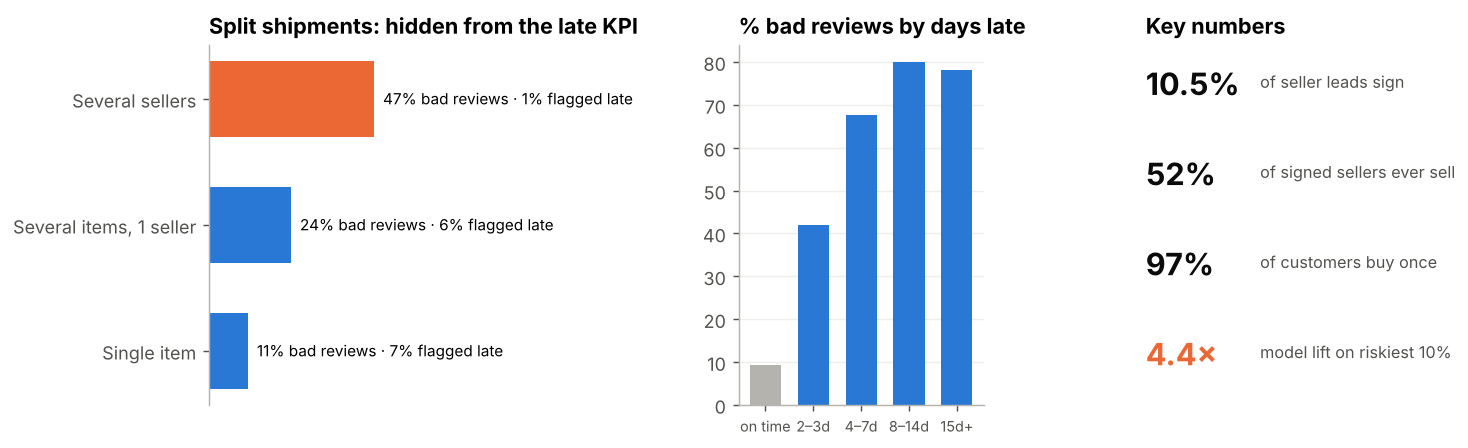

**The finding in one sentence:** orders that contain items from **several sellers** get a 1–2★ review **47%** of the time, versus 11% for single items. They arrive in pieces, yet only ~1% are flagged "late", so the company's main delivery KPI can't see them.

**What's in this notebook**
1. [Project charter](#charter)
2. [Setup](#setup)
3. [Data model and the customer_id trap](#datamodel)
4. [Data quality and definitions](#quality)
5. [Engine 1: the seller funnel](#funnel)
6. [Engine 2: do customers come back?](#retention)
7. [Root cause: what drives bad reviews](#rootcause)
8. [What customers say: classic NLP vs an LLM](#nlp)
9. [Predictive model for service recovery](#model)
10. [A/B test plan](#abtest)
11. [Interactive app](#app)
12. [Recommendations and limitations](#recs)

*Plotting code is folded by default: click "…" or "show code" to expand it. Every number in the text comes from the code right above it.*

<a id="charter"></a>
## 1. Project charter
| | |
|---|---|
| **Business question** | Where does Olist's growth leak (winning sellers, or keeping customers happy), and what should be fixed first? |
| **Stakeholders** | Head of Growth (seller funnel) · Head of Operations (logistics) · CRM/CX lead (service recovery) |
| **KPIs** | Lead→deal conversion · seller activation · repeat-purchase rate · % of 1–2★ reviews · late-delivery rate |
| **Data** | 9 linked e-commerce tables (~100k orders, 2016–2018) + 8,000 seller leads (marketing funnel) |
| **Out of scope** | Marketing spend (not in the data), so no ROI by channel |
| **Deliverables** | This notebook · SQL file · interactive dashboard · risk-scoring app · A/B test plan |

<a id="setup"></a>
## 2. Setup
**Tools:** DuckDB (a SQL database that runs inside Python), the `jupysql` extension so SQL gets its own cells, pandas for tables, matplotlib for charts, scikit-learn for machine learning.

*On Kaggle or Colab, first run:* `!pip install duckdb jupysql duckdb-engine`

In [1]:
import os, glob, re, unicodedata, warnings
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Find the CSV folder: works on Kaggle (/kaggle/input/...) and locally (./data)
DATA = next(p for p in ["data", "../data", "/kaggle/input"]
            if glob.glob(f"{p}/**/olist_orders_dataset.csv", recursive=True))
files = {os.path.basename(f)[:-4]: f for f in glob.glob(f"{DATA}/**/*.csv", recursive=True)}

names = {"olist_customers_dataset": "customers", "olist_geolocation_dataset": "geolocation",
         "olist_order_items_dataset": "order_items", "olist_order_payments_dataset": "payments",
         "olist_order_reviews_dataset": "reviews", "olist_orders_dataset": "orders",
         "olist_products_dataset": "products", "olist_sellers_dataset": "sellers",
         "product_category_name_translation": "category_translation",
         "olist_marketing_qualified_leads_dataset": "leads", "olist_closed_deals_dataset": "closed_deals"}

con = duckdb.connect()   # an in-memory SQL database
for stem, table in names.items():
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM read_csv_auto('{files[stem]}', header=true)")
print("Loaded:", ", ".join(names.values()))

Loaded: customers, geolocation, order_items, payments, reviews, orders, products, sellers, category_translation, leads, closed_deals


In [2]:
# Turn on SQL cells: from now on, a cell starting with %%sql is pure SQL run in DuckDB.
# "%%sql result <<" saves the answer as a pandas table called result.
%load_ext sql
%sql con --alias duckdb
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0

In [3]:
# Helpers: clean table display + one chart style for the whole notebook
def show(df, pct=(), ints=(), dec1=(), dec2=(), caption=None):
    fmt = {**{c: "{:.1f}%" for c in pct}, **{c: "{:,.0f}" for c in ints},
           **{c: "{:.1f}" for c in dec1}, **{c: "{:.2f}" for c in dec2}}
    st = df.style.format(fmt, na_rep="–").hide(axis="index")
    text_cols = [c for c in df.columns if df[c].dtype == object]
    st = st.set_properties(subset=text_cols, **{"text-align": "left"}).set_table_styles(
        [{"selector": "th", "props": [("text-align", "left")]}])
    return st.set_caption(caption) if caption else st

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#b5b3ad", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRAY, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.titlelocation": "left", "font.size": 10})
def hbar(labels, values, colors, title, xlabel, fmt="{:.0f}%", size=(7, 3.2)):
    fig, ax = plt.subplots(figsize=size)
    ax.barh(labels, values, color=colors, height=0.6)
    for y, v in enumerate(values):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=9, color=INK)
    ax.set_title(title); ax.set_xlabel(xlabel)
    ax.grid(axis="x", color="#eeeeec"); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()

<a id="datamodel"></a>
## 3. Data model and the customer_id trap
The 9 e-commerce tables join around **orders**; the 2 marketing tables join to them through **seller_id**, so a lead can be followed all the way to actual sales.

```
leads ──mql_id──> closed_deals ──seller_id──> order_items ──product_id──> products
customers ──customer_id──> orders ──order_id──> payments · reviews · order_items
```
**The trap:** a new `customer_id` is created for *every order*. The real person is `customer_unique_id`. Count the wrong one and everybody looks like a one-time buyer.

In [4]:
%%sql ids <<
SELECT count(*) AS customer_ids, count(DISTINCT customer_unique_id) AS real_people
FROM customers

In [5]:
show(ids, ints=["customer_ids", "real_people"])

customer_ids,real_people
"99,441","96,096"


<a id="quality"></a>
## 4. Data quality and definitions

In [6]:
%%sql status <<
SELECT order_status,
       count(*)                                          AS orders,
       100.0 * count(*) / sum(count(*)) OVER ()          AS pct      -- share of all orders
FROM orders
GROUP BY order_status
ORDER BY orders DESC

In [7]:
show(status, pct=["pct"], ints=["orders"])

order_status,orders,pct
delivered,"96,478",97.0%
shipped,"1,107",1.1%
canceled,625,0.6%
unavailable,609,0.6%
invoiced,314,0.3%
processing,301,0.3%
created,5,0.0%
approved,2,0.0%


In [8]:
%%sql checks <<
SELECT
  (SELECT count(*) FROM orders
    WHERE order_status = 'delivered' AND order_delivered_customer_date IS NULL) AS delivered_but_no_date,
  (SELECT count(*) - count(DISTINCT order_id) FROM reviews)                     AS extra_reviews_same_order,
  (SELECT round(100.0 * avg((review_comment_message IS NOT NULL)::int), 1) FROM reviews) AS pct_reviews_with_text

In [9]:
show(checks, ints=["delivered_but_no_date", "extra_reviews_same_order"], dec1=["pct_reviews_with_text"])

delivered_but_no_date,extra_reviews_same_order,pct_reviews_with_text
8,551,41.3


**Decisions:** keep only delivered orders with a delivery date · average the reviews when an order has two (otherwise those orders would be counted twice: "fan-out") · **late** = delivered more than 1 day after the promised date · **bad review** = 1–2★.

These rules are saved once as a SQL **view** (a saved query that behaves like a table), so every later step uses identical definitions.

In [10]:
%%sql _view <<
CREATE OR REPLACE VIEW v_orders AS
SELECT o.order_id, c.customer_unique_id, c.customer_state,
       o.order_purchase_timestamp                                                         AS ts,
       o.order_delivered_customer_date                                                    AS delivered,
       o.order_estimated_delivery_date                                                    AS promised,
       date_diff('day', o.order_purchase_timestamp, o.order_delivered_customer_date)      AS delivery_days,
       date_diff('day', o.order_estimated_delivery_date, o.order_delivered_customer_date) AS days_vs_promise,
       o.order_delivered_customer_date > o.order_estimated_delivery_date + INTERVAL 1 DAY AS is_late,
       r.review_score,
       i.n_items, i.n_sellers
FROM orders o
JOIN customers c USING (customer_id)
LEFT JOIN (SELECT order_id, avg(review_score) AS review_score            -- one row per order first
           FROM reviews GROUP BY order_id) r USING (order_id)
LEFT JOIN (SELECT order_id, count(*) AS n_items, count(DISTINCT seller_id) AS n_sellers
           FROM order_items GROUP BY order_id) i USING (order_id)
WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL

In [11]:
%%sql base <<
SELECT count(*) AS delivered_orders, 100 * avg(is_late::int) AS pct_late,
       avg(delivery_days) AS avg_delivery_days, avg(review_score) AS avg_review
FROM v_orders

In [12]:
show(base, pct=["pct_late"], ints=["delivered_orders"], dec1=["avg_delivery_days"], dec2=["avg_review"])

delivered_orders,pct_late,avg_delivery_days,avg_review
"96,470",6.8%,12.5,4.16


<a id="funnel"></a>
## 5. Engine 1: the seller funnel
Olist's sales team receives **marketing-qualified leads** (sellers who filled in a form) and tries to sign them. Which channels bring leads that sign, and do signed sellers actually sell?

In [13]:
%%sql funnel <<
SELECT coalesce(l.origin, 'unknown')                               AS channel,
       count(*)                                                    AS leads,
       count(d.mql_id)                                             AS deals_won,
       100.0 * count(d.mql_id) / count(*)                          AS conversion_pct,
       median(date_diff('day', l.first_contact_date, d.won_date))  AS median_days_to_close
FROM leads l
LEFT JOIN closed_deals d USING (mql_id)      -- keeps leads that never signed
GROUP BY 1
ORDER BY leads DESC

In [14]:
total = funnel[["leads", "deals_won"]].sum()
print(f"Overall: {total.deals_won:,} deals from {total.leads:,} leads = {100*total.deals_won/total.leads:.1f}% conversion")
show(funnel, pct=["conversion_pct"], ints=["leads", "deals_won", "median_days_to_close"])

Overall: 842 deals from 8,000 leads = 10.5% conversion


channel,leads,deals_won,conversion_pct,median_days_to_close
organic_search,"2,296",271,11.8%,14
paid_search,"1,586",195,12.3%,15
social,"1,350",75,5.6%,30
unknown,"1,159",193,16.7%,11
direct_traffic,499,56,11.2%,10
email,493,15,3.0%,21
referral,284,24,8.5%,18
other,150,4,2.7%,9
display,118,6,5.1%,8
other_publicities,65,3,4.6%,35


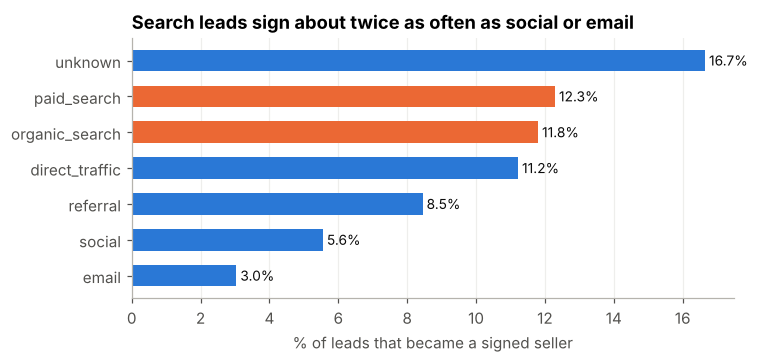

In [15]:
f = funnel[funnel.leads >= 250].sort_values("conversion_pct")
hbar(f.channel, f.conversion_pct, [ORANGE if "search" in c else BLUE for c in f.channel],
     "Search leads sign about twice as often as social or email", "% of leads that became a signed seller", "{:.1f}%", (7, 3.4))

**Reading it:** search (orange) brings the most leads *and* converts at ~12%; social and email convert at 3–6% and take longer. "unknown" converts best but is untracked, so **fix lead-source tracking**.

**Activation:** do signed sellers sell? Orders end in Aug 2018, so only sellers won **Jan–May 2018** are counted (each had 3+ months).

In [16]:
%%sql activation <<
WITH sellers_who_sold AS (SELECT DISTINCT seller_id FROM order_items)
SELECT CASE WHEN GROUPING(d.business_segment) = 1 THEN 'ALL SEGMENTS' ELSE d.business_segment END AS business_segment,
       count(*)                                         AS sellers_won,
       count(s.seller_id)                               AS sellers_with_a_sale,
       100.0 * count(s.seller_id) / count(*)            AS activation_pct
FROM closed_deals d
LEFT JOIN sellers_who_sold s USING (seller_id)
WHERE d.won_date >= '2018-01-01' AND d.won_date < '2018-06-01'
GROUP BY ROLLUP (d.business_segment)          -- ROLLUP adds the total row
ORDER BY sellers_won DESC

In [17]:
show(activation.head(8), pct=["activation_pct"], ints=["sellers_won", "sellers_with_a_sale"])

business_segment,sellers_won,sellers_with_a_sale,activation_pct
ALL SEGMENTS,662,344,52.0%
home_decor,83,40,48.2%
health_beauty,76,42,55.3%
car_accessories,64,29,45.3%
household_utilities,58,39,67.2%
construction_tools_house_garden,54,30,55.6%
audio_video_electronics,45,26,57.8%
pet,26,16,61.5%


**Reading it:** only about **half (52%)** of sellers won Jan–May 2018 made any sale by August. A signed deal that never sells is worth nothing → track **"first sale within 30 days"**, not just deals won. *(The public orders data may be a sample, so the true rate could be higher.)*

<a id="retention"></a>
## 6. Engine 2: do customers come back?

In [18]:
%%sql repeat <<
WITH per_person AS (SELECT customer_unique_id, count(*) AS orders FROM v_orders GROUP BY 1)
SELECT CASE WHEN orders >= 3 THEN '3+' ELSE orders::varchar END AS orders_per_customer,
       count(*) AS customers,
       100.0 * count(*) / sum(count(*)) OVER () AS pct
FROM per_person GROUP BY 1 ORDER BY 1

In [19]:
show(repeat, pct=["pct"], ints=["customers"])

orders_per_customer,customers,pct
1,"90,549",97.0%
2,"2,573",2.8%
3+,228,0.2%


**97% buy only once**, partly because loyalty goes to the marketplace, not the Olist seller. Does a **bad first experience** make it worse? Only first orders before March 2018 count, so everyone had at least 6 months to return (a fair **observation window**).

In [20]:
%%sql first_exp <<
WITH ranked AS (
  SELECT *,
         row_number() OVER (PARTITION BY customer_unique_id ORDER BY ts) AS nth_order,     -- 1 = first order
         count(*)     OVER (PARTITION BY customer_unique_id)             AS total_orders   -- did they come back?
  FROM v_orders),
firsts AS (SELECT * FROM ranked WHERE nth_order = 1 AND ts < '2018-03-01' AND review_score IS NOT NULL)
SELECT CASE WHEN review_score <= 2 AND is_late THEN 'Late + bad review'
            WHEN review_score <= 2            THEN 'On time, bad review'
            WHEN is_late                      THEN 'Late, OK review'
            ELSE                                   'On time, OK review' END AS first_experience,
       count(*) AS customers,
       100.0 * avg((total_orders > 1)::int) AS pct_came_back
FROM firsts GROUP BY 1 ORDER BY pct_came_back DESC

In [21]:
show(first_exp, pct=["pct_came_back"], ints=["customers"])

first_experience,customers,pct_came_back
"On time, OK review","46,631",4.1%
"On time, bad review","4,891",3.9%
"Late, OK review","1,243",3.8%
Late + bad review,"2,346",2.8%


**Reading it:** a smooth first order brings back **4.1%**; a late order with a bad review brings back **2.8%**, about a third fewer.

<a id="rootcause"></a>
## 7. Root cause: what drives bad reviews?
### 7a. Delay

In [22]:
%%sql late_bins <<
SELECT CASE WHEN days_vs_promise <= 1  THEN '1. On time (≤1 day late)'
            WHEN days_vs_promise <= 3  THEN '2. 2–3 days late'
            WHEN days_vs_promise <= 7  THEN '3. 4–7 days late'
            WHEN days_vs_promise <= 14 THEN '4. 8–14 days late'
            ELSE                            '5. 15+ days late' END AS delivery,
       count(*)                               AS orders,
       avg(review_score)                      AS avg_stars,
       100.0 * avg((review_score <= 2)::int)  AS pct_bad_review
FROM v_orders WHERE review_score IS NOT NULL
GROUP BY 1 ORDER BY 1

In [23]:
%%sql overall <<
SELECT is_late, 100.0 * avg((review_score <= 2)::int) AS pct_bad
FROM v_orders WHERE review_score IS NOT NULL GROUP BY 1

In [24]:
ov = overall.set_index("is_late").pct_bad
print(f"On-time orders: {ov[False]:.1f}% get 1–2★ · Late orders: {ov[True]:.1f}% get 1–2★")
show(late_bins, pct=["pct_bad_review"], ints=["orders"], dec2=["avg_stars"])

On-time orders: 9.2% get 1–2★ · Late orders: 62.4% get 1–2★


delivery,orders,avg_stars,pct_bad_review
1. On time (≤1 day late),"90,263",4.29,9.3%
2. 2–3 days late,"1,032",2.94,42.1%
3. 4–7 days late,"1,748",2.11,67.6%
4. 8–14 days late,"1,446",1.67,80.1%
5. 15+ days late,"1,335",1.73,78.2%


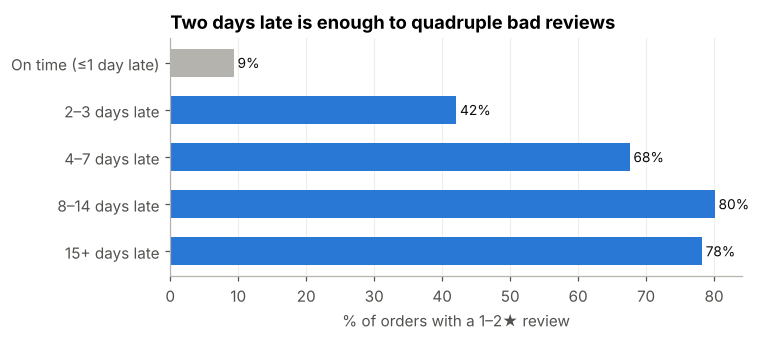

In [25]:
lb = late_bins.iloc[::-1]
hbar(lb.delivery.str[3:], lb.pct_bad_review, [BLUE] * (len(lb) - 1) + [GRAY],
     "Two days late is enough to quadruple bad reviews", "% of orders with a 1–2★ review")

### 7b. When and where

In [26]:
%%sql monthly <<
SELECT date_trunc('month', ts) AS month, count(*) AS orders,
       100 * avg(is_late::int) AS pct_late, avg(review_score) AS avg_stars
FROM v_orders WHERE ts >= '2017-01-01' AND ts < '2018-09-01'
GROUP BY 1 ORDER BY 1

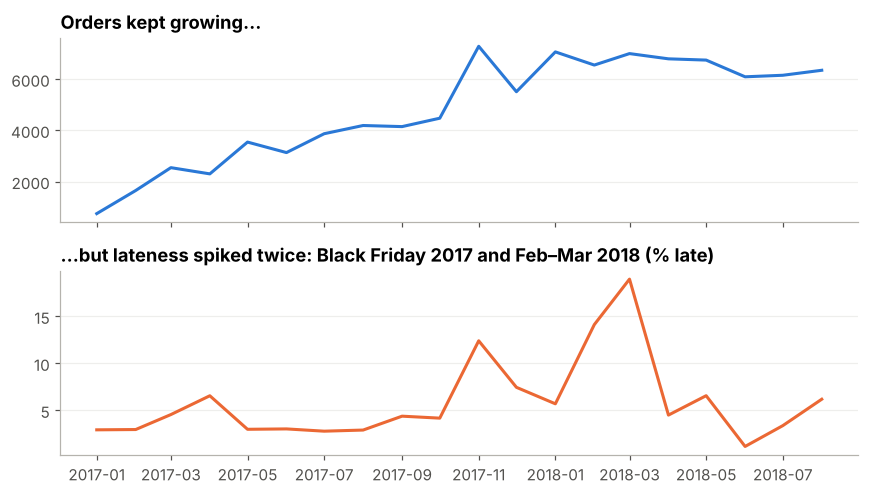

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
axes[0].plot(monthly.month, monthly.orders, color=BLUE, lw=2); axes[0].set_title("Orders kept growing…")
axes[1].plot(monthly.month, monthly.pct_late, color=ORANGE, lw=2); axes[1].set_title("…but lateness spiked twice: Black Friday 2017 and Feb–Mar 2018 (% late)")
for a in axes: a.grid(axis="y", color="#eeeeec")
plt.tight_layout(); plt.show()

In [28]:
%%sql states <<
SELECT customer_state AS state, count(*) AS orders, 100 * avg(is_late::int) AS pct_late,
       avg(delivery_days) AS avg_days, avg(review_score) AS avg_stars
FROM v_orders GROUP BY 1 HAVING count(*) >= 300 ORDER BY pct_late DESC

In [29]:
show(states.head(6), pct=["pct_late"], ints=["orders"], dec1=["avg_days"], dec2=["avg_stars"])

state,orders,pct_late,avg_days,avg_stars
AL,397,21.4%,24.5,3.85
MA,717,17.4%,21.5,3.83
SE,335,15.2%,21.5,3.91
PI,476,13.9%,19.4,3.99
CE,"1,279",13.8%,21.2,3.94
BA,"3,256",12.2%,19.3,3.93


**Reading it:** lateness is usually 3–5% but hit 12% at Black Friday 2017 and 14–19% in Feb–Mar 2018, a spike volume doesn't explain (a question for Operations). North-East states wait 20+ days and are late 14–21% of the time, versus 4.5% in São Paulo.

### 7c. The hidden problem: split shipments

In [30]:
%%sql split <<
SELECT CASE WHEN n_sellers > 1 THEN 'Several sellers'
            WHEN n_items > 1   THEN 'Several items, 1 seller'
            ELSE                    'Single item' END AS order_type,
       count(*)                                   AS orders,
       100.0 * avg((review_score <= 2)::int)      AS pct_bad_review,
       100.0 * avg(is_late::int)                  AS pct_flagged_late
FROM v_orders WHERE review_score IS NOT NULL
GROUP BY 1 ORDER BY pct_bad_review

In [31]:
show(split, pct=["pct_bad_review", "pct_flagged_late"], ints=["orders"])

order_type,orders,pct_bad_review,pct_flagged_late
Single item,"86,296",11.2%,6.8%
"Several items, 1 seller","8,267",23.5%,5.8%
Several sellers,"1,261",47.3%,1.0%


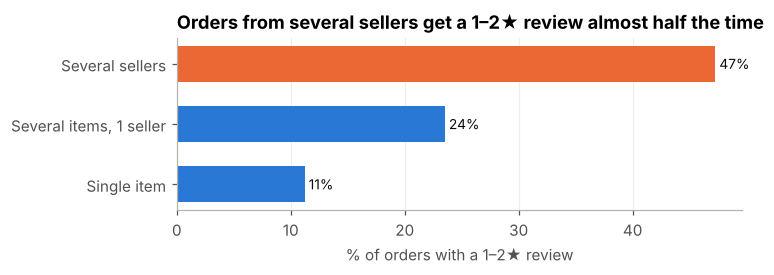

In [32]:
hbar(split.order_type, split.pct_bad_review, [BLUE, BLUE, ORANGE],
     "Orders from several sellers get a 1–2★ review almost half the time", "% of orders with a 1–2★ review", size=(7, 2.6))

**Reading it:** multi-seller orders get a bad review **47%** of the time, 4× single items, yet only ~1% are flagged late. Each seller ships separately, so customers receive the order **in pieces**; the system likely marks it delivered when the first package lands, which hides the problem from the late-delivery KPI. Section 8 checks this in the customers' own words.

<a id="nlp"></a>
## 8. What customers say: classic NLP vs an LLM
**8a. Topic modeling (classic NLP).** TF-IDF turns each 1–2★ comment into numbers (distinctive words score high); NMF finds 8 groups of words that appear together (*topics*), which I then named by reading them.

In [33]:
%%sql bad <<
SELECT review_id, review_comment_message AS text
FROM reviews
WHERE review_score <= 2 AND review_comment_message IS NOT NULL
ORDER BY review_id

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

def clean(s):
    s = unicodedata.normalize("NFKD", s.lower())
    s = "".join(ch for ch in s if not unicodedata.combining(ch))   # não -> nao
    return re.sub(r"[^a-z ]", " ", s)

stop = set('''a o e de do da dos das que nao em um uma para com por no na nos nas se mais mas como foi ao aos ja eu
meu minha me ele ela isso este esta esse essa ate muito so pois pelo pela ser sao tem ter estou estava fiz fez bem
ainda sem quando ou tambem entao porem lhe seu sua vou vai aqui la todo toda todos tudo nada outro outra outros mesmo
hoje dia dias produto produtos'''.split())

vec = TfidfVectorizer(stop_words=list(stop), min_df=20, max_df=0.5, ngram_range=(1, 2))
X_text = vec.fit_transform(bad.text.map(clean))
nmf = NMF(n_components=8, random_state=0, init="nndsvd", max_iter=400).fit(X_text)
terms = np.array(vec.get_feature_names_out())
for i, comp in enumerate(nmf.components_):
    print(f"Topic {i}: {', '.join(terms[comp.argsort()[::-1][:8]])}")
print(f"\n{len(bad):,} comments analyzed")

Topic 0: recebi, momento, momento recebi, agora recebi, recebi apenas, recebi mercadoria, posso, avaliar
Topic 1: chegou, agora chegou, quebrado, prazo, chegou prazo, era, pedido chegou, nunca
Topic 2: entregue, consta, momento, pedido, pedido entregue, entregue prazo, consta entregue, momento entregue
Topic 3: veio, defeito, veio defeito, pedi, errado, veio errado, faltando, veio faltando
Topic 4: entrega, prazo, prazo entrega, demora, passou, demora entrega, passou prazo, atraso
Topic 5: comprei, dois, apenas, comprei dois, recebi apenas, duas, unidades, entregaram
Topic 6: compra, loja, quero, pedido, agora, aguardando, dinheiro, lannister
Topic 7: qualidade, pessima, pessima qualidade, gostei, ruim, recomendo, material, foto

10,890 comments analyzed


| # | Key words | Meaning | Theme I named it |
|---|---|---|---|
| 0 | *recebi, até o momento* | haven't received it so far | Not received yet |
| 1 | *chegou, quebrado, prazo* | arrived, broken, deadline | Arrived late or broken |
| 2 | *consta entregue* | shows as delivered | Marked delivered, not received |
| 3 | *veio defeito, errado, faltando* | came defective / wrong / missing | Defective or wrong item |
| 4 | *prazo entrega, demora, atraso* | delivery deadline, delay | Late delivery |
| 5 | *comprei dois, recebi apenas* | bought two, received only one | **Incomplete order** |
| 6 | *aguardando, dinheiro, quero* | waiting, money, I want | Waiting / wants refund |
| 7 | *qualidade, péssima, foto* | quality, terrible, photo | Poor quality / not as pictured |

In [35]:
theme_names = ["Not received yet", "Arrived late or broken", "Marked delivered, not received", "Defective or wrong item",
               "Late delivery", "Incomplete order", "Waiting / wants refund", "Poor quality / not as pictured"]
product_themes = {"Defective or wrong item", "Poor quality / not as pictured"}
group = lambda t: "Other" if t == "Other" else ("Product" if t in product_themes else "Delivery")

W = nmf.transform(X_text)
has_topic = W.max(axis=1) > 0
bad["theme"] = np.where(has_topic, np.array(theme_names)[W.argmax(axis=1)], "Unclassified")
share = bad.loc[has_topic, "theme"].value_counts(normalize=True).mul(100)
deliv = share[[t for t in share.index if group(t) == "Delivery"]].sum()
rest = share.drop("Waiting / wants refund")
deliv_rest = 100 * rest[[t for t in rest.index if group(t) == "Delivery"]].sum() / rest.sum()
print(f"Delivery-related share of classified 1–2★ comments: {deliv:.0f}%  (without the broad 'Waiting' topic: {deliv_rest:.0f}%)")
show(share.rename("pct").reset_index().rename(columns={"index": "theme"}), pct=["pct"])

Delivery-related share of classified 1–2★ comments: 79%  (without the broad 'Waiting' topic: 70%)


theme,pct
Waiting / wants refund,27.7%
Incomplete order,13.5%
Defective or wrong item,13.0%
Late delivery,12.1%
Not received yet,11.0%
"Marked delivered, not received",9.1%
Poor quality / not as pictured,8.5%
Arrived late or broken,5.2%


**8b. In their own words.** Real comments from the data, with my English translations (Portuguese is close to French and Spanish, which I speak):

In [36]:
quotes = {  # review_id: (theme, my translation)
 "559d0de3fbceb6ea4bd7b5cd18e23ad5": ("Incomplete order", "I bought two units, only one was delivered."),
 "5270574b820e27ed76cdb13a6dfc4391": ("Incomplete order", "I paid for the full kit (shampoo, conditioner and curl activator) and only received the curl activator. That's wrong."),
 "3dc1a097f2f5b5798e96e2dd0f35d928": ("Marked delivered, not received", "My account says the product was delivered, but it still hasn't arrived (March 26); I complained on March 30."),
 "38d0c8c8a7ae5eedd6a5d3afc87b72aa": ("Not received yet", "Very slow, I still haven't received the product."),
 "d6d1e908191ce44ad6b1625fea2dd4bd": ("Late delivery", "The delivery was so late I was about to cancel."),
 "bde3a6bc851b615b1b91add03433f656": ("Defective or wrong item", "I bought the product with a 2019 expiry date; it came with 2018."),
 "8491feec182f0f1e300691948ca286aa": ("Poor quality / not as pictured", "The color is different from the photo."),
 "0a6e2e7c3e4365bcac45d499b1a9d6c7": ("Waiting / wants refund", "Don't recommend. Didn't receive it. I want a refund."),
}
q = bad.set_index("review_id").loc[list(quotes), ["text"]]
q["theme"] = [quotes[i][0] for i in q.index]
q["english"] = [quotes[i][1] for i in q.index]
q["text"] = q.text.str.split().str.join(" ")
show(q[["theme", "text", "english"]].rename(columns={"text": "customer wrote (Portuguese)", "english": "English"}))

theme,customer wrote (Portuguese),English
Incomplete order,"Comprei duas unidades , apenas uma foi entregue.","I bought two units, only one was delivered."
Incomplete order,"Paguei pelo Kit completo:shampoo,condicionador e ativador de cachos e recebi apenas o ativador de cachos,isso tá errado","I paid for the full kit (shampoo, conditioner and curl activator) and only received the curl activator. That's wrong."
"Marked delivered, not received","na conta consta que o produto foi entregue mas até o momento não entregue dia 26/03,feito a reclamação 30/03","My account says the product was delivered, but it still hasn't arrived (March 26); I complained on March 30."
Not received yet,"Muita demora, até o momento não recebi o produto","Very slow, I still haven't received the product."
Late delivery,"A entrega atrasou demais, eu já estava cancelando.",The delivery was so late I was about to cancel.
Defective or wrong item,Comprei o produto com a data de validade ate 2019 veio 2018,I bought the product with a 2019 expiry date; it came with 2018.
Poor quality / not as pictured,A cor e diferente de como está na foto,The color is different from the photo.
Waiting / wants refund,Não recomendo. Não recebi. Quero reembolso.,Don't recommend. Didn't receive it. I want a refund.


**8c. Does an LLM agree with the topic model?** Topic models are fast and free but rough. I gave a large language model (Claude) the same 8 themes plus "Other" and had it label a **random sample of 300** classified comments, then compared its labels with NMF's.

*How the labels were made:* `llm_labels.csv` holds labels produced by Claude (Opus 5.5) in a chat session, using the same instructions as the prompt below. To regenerate them yourself through the API, set `RUN_LLM = True` and add your `ANTHROPIC_API_KEY` (300 short reviews cost well under $1; results will differ slightly from run to run).

In [37]:
RUN_LLM = False
sample = bad[bad.theme != "Unclassified"].sample(300, random_state=42)
llm_choices = theme_names + ["Other"]

if RUN_LLM:
    import anthropic
    client = anthropic.Anthropic()
    prompt = ("You label Brazilian e-commerce reviews written in Portuguese. Pick exactly one theme from this list: "
              + "; ".join(llm_choices) + ". Use 'Not received yet' when the customer never got the order, "
              "'Late delivery' when it arrived late, and 'Other' when no theme fits. Reply with the theme only.\n\nReview: ")
    def llm_label(text):
        msg = client.messages.create(model="claude-haiku-4-5", max_tokens=20,
                                     messages=[{"role": "user", "content": prompt + text}])
        return msg.content[0].text.strip()
    sample["llm_theme"] = sample.text.map(llm_label)
    sample[["review_id", "llm_theme"]].to_csv("llm_labels.csv", index=False)

if os.path.exists("llm_labels.csv"):
    cmp_ = sample.merge(pd.read_csv("llm_labels.csv"), on="review_id")
    exact = 100 * (cmp_.theme == cmp_.llm_theme).mean()
    same_group = 100 * (cmp_.theme.map(group) == cmp_.llm_theme.map(group)).mean()
    llm_known = cmp_[cmp_.llm_theme != "Other"]
    llm_deliv = 100 * (llm_known.llm_theme.map(group) == "Delivery").mean()
    print(f"Reviews compared: {len(cmp_)}")
    print(f"Exact same theme:                    {exact:.0f}%")
    print(f"Same big group (delivery vs product): {same_group:.0f}%")
    print(f"Delivery share, NMF vs LLM:           {deliv:.0f}% vs {llm_deliv:.0f}% (LLM 'Other' excluded)")
    side = pd.DataFrame({"NMF": cmp_.theme.value_counts(normalize=True), "LLM": cmp_.llm_theme.value_counts(normalize=True)}).fillna(0).mul(100)
    display(show(side.sort_values("LLM", ascending=False).reset_index().rename(columns={"index": "theme"}), pct=["NMF", "LLM"],
                 caption="Share of the 300 sampled comments per theme"))
else:
    print("llm_labels.csv not found: download it from the GitHub repo, or set RUN_LLM = True.")

Reviews compared: 300
Exact same theme:                    29%
Same big group (delivery vs product): 64%
Delivery share, NMF vs LLM:           79% vs 68% (LLM 'Other' excluded)


theme,NMF,LLM
Not received yet,12.0%,30.3%
Defective or wrong item,16.3%,19.3%
Incomplete order,11.3%,13.3%
Other,0.0%,11.0%
Poor quality / not as pictured,9.3%,9.3%
Waiting / wants refund,26.7%,6.7%
Late delivery,14.3%,5.3%
Arrived late or broken,4.0%,3.7%
"Marked delivered, not received",6.0%,1.0%


**Reading it: the honest answer is "yes and no".**
- On **individual comments** the two methods often disagree (exact match on under a third). NMF's biggest topic, "Waiting / wants refund", turns out to be a catch-all: the LLM files many of those comments under "Not received yet", "Defective or wrong item" or "Other".
- On the **big picture** they agree: both say most complaints are about **delivery** (about 4 in 5 for NMF, about 2 in 3 for the LLM) and both find **incomplete orders in ~13%** of complaints (NMF: 13.5% of all comments; LLM: 13.3% of its sample), which confirms the split-shipment finding with a second, independent method.
- **Lesson:** a topic model is good for a fast overview; an LLM is better for labeling individual comments. In production I'd use the LLM for labels and keep NMF to discover new themes.

<a id="model"></a>
## 9. Predictive model: flag likely bad reviews *before* they're written
**Use case:** Olist sends the review survey on delivery. If we can predict which customers are about to leave 1–2★, a CRM flow can reach them first (*service recovery*).

**Honesty rules:** only information known at delivery time · a seller's track record counts only orders delivered *before* this purchase · train on 2017, test on 2018.

In [38]:
%%sql model_df <<
WITH items AS (
  SELECT oi.order_id, count(*) AS n_items, count(DISTINCT oi.seller_id) AS n_sellers,
         sum(price) AS price, sum(freight_value) AS freight, min(oi.seller_id) AS seller_id,
         min(p.product_category_name) AS category, sum(p.product_weight_g) AS weight_g
  FROM order_items oi LEFT JOIN products p USING (product_id) GROUP BY 1),
base AS (
  SELECT v.order_id, v.ts, v.delivered, v.customer_state, s.seller_state, i.seller_id, i.category,
         i.n_items, i.n_sellers, i.price, i.freight, i.weight_g,
         date_diff('day', v.ts, v.promised)                                   AS promised_days,
         v.delivery_days, v.days_vs_promise, v.is_late::int                   AS is_late,
         date_diff('day', o.order_approved_at, o.order_delivered_carrier_date) AS days_to_ship,
         (v.review_score <= 2)::int                                           AS bad_review
  FROM v_orders v JOIN items i USING (order_id) JOIN orders o USING (order_id)
  LEFT JOIN sellers s ON s.seller_id = i.seller_id
  WHERE v.review_score IS NOT NULL),
history AS (   -- seller's late rate on orders delivered BEFORE this purchase (no peeking into the future)
  SELECT b.order_id, count(p.order_id) AS seller_prior_orders, avg(p.is_late) AS seller_prior_late_rate
  FROM base b LEFT JOIN base p ON p.seller_id = b.seller_id AND p.delivered < b.ts
  GROUP BY 1)
SELECT * FROM base JOIN history USING (order_id)
ORDER BY order_id

In [39]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits   # one thread = identical results on every run

model_df["same_state"] = (model_df.customer_state == model_df.seller_state).astype(int)
model_df["freight_share"] = model_df.freight / model_df.price
numeric = ["days_vs_promise", "delivery_days", "days_to_ship", "promised_days", "n_items", "n_sellers",
           "price", "freight", "freight_share", "weight_g", "seller_prior_orders", "seller_prior_late_rate", "same_state"]
categorical = ["customer_state", "seller_state", "category"]
for c in categorical:
    model_df[c] = model_df[c].fillna("unknown").astype("category")

X, y = model_df[numeric + categorical], model_df.bad_review
train, test = model_df.ts < "2018-01-01", model_df.ts >= "2018-01-01"

with threadpool_limits(1):
    model = HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=300,
                                           learning_rate=0.05, random_state=0).fit(X[train], y[train])
    risk = model.predict_proba(X[test])[:, 1]
print(f"{len(model_df):,} orders · {y.mean():.1%} got a 1–2★ review")
print(f"Train: {train.sum():,} orders (2016–2017) · Test: {test.sum():,} orders (2018)")
print(f"AUC on 2018 orders: {roc_auc_score(y[test], risk):.2f}   (0.5 = coin flip, 1.0 = perfect)")

95,824 orders · 12.8% got a 1–2★ review
Train: 43,362 orders (2016–2017) · Test: 52,462 orders (2018)
AUC on 2018 orders: 0.77   (0.5 = coin flip, 1.0 = perfect)


**What AUC 0.77 means:** take one customer who left a bad review and one who didn't. In 77% of such pairs the model gives the unhappy one the higher risk score. **What a manager wants:** if the team can contact 10% of customers, how many unhappy ones does it reach?

In [40]:
yt, base_rate = y[test].values, y[test].mean()
rows = []
for frac in [0.05, 0.10, 0.20]:
    top = np.argsort(-risk)[: int(frac * len(risk))]
    rows.append({"who we contact": f"Model: riskiest {frac:.0%}", "orders": len(top),
                 "% unhappy": 100 * yt[top].mean(), "% of all 1–2★ caught": 100 * yt[top].sum() / yt.sum(),
                 "lift vs random": yt[top].mean() / base_rate})
late = model_df.loc[test, "is_late"].values == 1
rows.append({"who we contact": "Rule: all late orders", "orders": late.sum(), "% unhappy": 100 * yt[late].mean(),
             "% of all 1–2★ caught": 100 * yt[late].sum() / yt.sum(), "lift vs random": yt[late].mean() / base_rate})
lift = pd.DataFrame(rows)
show(lift, pct=["% unhappy", "% of all 1–2★ caught"], ints=["orders"], dec1=["lift vs random"])

who we contact,orders,% unhappy,% of all 1–2★ caught,lift vs random
Model: riskiest 5%,"2,623",77.4%,29.0%,5.8
Model: riskiest 10%,"5,246",59.0%,44.2%,4.4
Model: riskiest 20%,"10,492",38.6%,57.8%,2.9
Rule: all late orders,"3,994",62.9%,35.9%,4.7


**Reading it:** the model's **top 10%** are ~**4.4×** more likely than average to leave 1–2★ and include **44%** of all bad reviews. The "late orders only" rule catches 36% and misses split shipments entirely, because they don't look late.

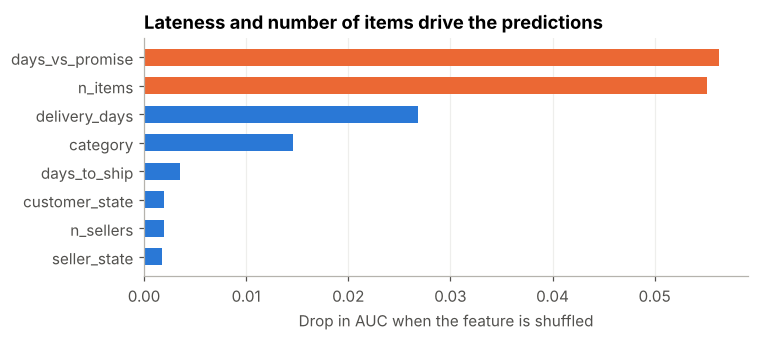

In [41]:
from sklearn.inspection import permutation_importance
with threadpool_limits(1):
    imp = permutation_importance(model, X[test], y[test], scoring="roc_auc", n_repeats=3, random_state=0)
imp = pd.Series(imp.importances_mean, index=numeric + categorical).sort_values().tail(8)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(imp.index, imp.values, color=[ORANGE if i in ("days_vs_promise", "n_items") else BLUE for i in imp.index], height=0.6)
ax.set_title("Lateness and number of items drive the predictions"); ax.set_xlabel("Drop in AUC when the feature is shuffled")
ax.grid(axis="x", color="#eeeeec"); ax.set_axisbelow(True); plt.tight_layout(); plt.show()

SQL, the review text and the model point to the same two problems: **lateness** and **multi-item orders**. *(A model predicting lateness at purchase time only reached AUC ≈ 0.66: lateness comes from operational shocks that order details can't see, so I dropped it.)*

<a id="abtest"></a>
## 10. A/B test plan: does the service-recovery flow work?
A model is only valuable if acting on it changes the outcome, so the CRM flow must be **tested**, not assumed.

| | |
|---|---|
| **Who** | Each day's riskiest 10% of delivered orders (model score) |
| **Treatment** | Proactive message before the review survey: apology, tracking help for missing parts, voucher |
| **Control** | Nothing changes |
| **Assignment** | Random 50/50, by order |
| **Primary metric** | % of orders with a 1–2★ review |
| **Guardrails** | Voucher cost per order · refund rate · unsubscribe rate |
| **Decision rule** | Roll out if bad reviews drop significantly (α = 0.05) and cost per avoided bad review is acceptable |

In [42]:
from scipy.stats import norm
p_control = yt[np.argsort(-risk)[: int(0.10 * len(risk))]].mean()   # bad-review rate in the riskiest 10% today
relative_drop = 0.15                                                  # smallest improvement worth detecting
p_treat = p_control * (1 - relative_drop)
alpha, power = 0.05, 0.80
z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
n_per_group = int(np.ceil(z**2 * (p_control*(1-p_control) + p_treat*(1-p_treat)) / (p_control - p_treat)**2))

days = (model_df.loc[test, "ts"].max() - model_df.loc[test, "ts"].min()).days
eligible_per_day = 0.10 * test.sum() / days
print(f"Bad-review rate in the riskiest 10% (control): {p_control:.1%} → goal with treatment: {p_treat:.1%}")
print(f"Orders needed: {n_per_group:,} per group, {2*n_per_group:,} in total")
print(f"Eligible orders per day in this data: ~{eligible_per_day:.0f} → test duration ≈ {2*n_per_group/eligible_per_day/7:.0f} weeks")

Bad-review rate in the riskiest 10% (control): 59.0% → goal with treatment: 50.1%
Orders needed: 493 per group, 986 in total
Eligible orders per day in this data: ~22 → test duration ≈ 6 weeks


**Reading it:** to detect a 15% relative drop in bad reviews with 80% power, the test needs roughly a thousand high-risk orders in total, about **6 weeks** at this dataset's volume (less at Olist's real volume, since the public data is a sample).

<a id="app"></a>
## 11. Interactive app
The model is saved below and powers a small **Streamlit** web app (`app/app.py` in the repo): enter an order's details and see its risk of a 1–2★ review, compared with the average, plus what drives it.

In [43]:
import joblib, json
os.makedirs("outputs", exist_ok=True)
bundle = {"model": model, "numeric": numeric, "categorical": categorical,
          "categories": {c: list(model_df[c].cat.categories) for c in categorical},
          "defaults": {**{c: float(model_df.loc[train, c].median()) for c in numeric},
                       **{c: str(model_df.loc[train, c].mode()[0]) for c in categorical}},
          "base_rate": float(base_rate), "auc": float(roc_auc_score(y[test], risk)),
          "risk_percentiles": np.percentile(risk, np.arange(101)).tolist()}   # to say "riskier than X% of orders"
joblib.dump(bundle, "outputs/bad_review_model.joblib")
print("Saved outputs/bad_review_model.joblib")

Saved outputs/bad_review_model.joblib


<a id="recs"></a>
## 12. Recommendations and limitations
| Priority | Action | Owner | Evidence | KPI |
|---|---|---|---|---|
| **1** | **Fix split shipments:** hold "delivered" and the review survey until every package arrives; tell customers upfront when items ship separately | Operations + Product | Multi-seller orders: 47% bad reviews vs 11%; "bought two, received one" in ~13% of complaints (NMF and LLM agree) | % bad reviews on multi-seller orders |
| **2** | **Service-recovery CRM flow**, proven with the A/B test above | CRM / CX | Riskiest 10% are ~4.4× more likely to be unhappy; 44% of bad reviews reached | Bad-review rate, treatment vs control |
| **3** | **Realistic delivery dates in the North-East** + carrier capacity before peaks | Operations | NE late 14–21%; spikes at Black Friday and Feb–Mar 2018 | Late %, by state and month |
| **4** | **Seller activation KPI** + shift lead spend to search | Growth / Sales | ~10% conversion; ~half of won sellers never sold; search converts ~2× social/email | Activation %, conversion by channel |

**Limitations:** anonymized and probably sampled data · no marketing spend, so no ROI by channel · retention effects are correlations · the split-shipment explanation is a strongly supported hypothesis to confirm with shipment-level data · LLM labels cover a 300-comment sample.

In [44]:
# Export clean tables (dashboard / Tableau) and the summary graphic shown at the top
funnel.to_csv("outputs/funnel_by_channel.csv", index=False)
monthly.to_csv("outputs/monthly_delivery.csv", index=False)
states.to_csv("outputs/state_delivery.csv", index=False)
late_bins.to_csv("outputs/delay_vs_reviews.csv", index=False)
split.to_csv("outputs/order_type_reviews.csv", index=False)
share.rename("pct").reset_index().rename(columns={"index": "theme"}).to_csv("outputs/review_themes.csv", index=False)
lift.to_csv("outputs/model_lift.csv", index=False)

fig = plt.figure(figsize=(12, 3.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.35, 0.9, 1], wspace=0.55)
ax = fig.add_subplot(gs[0]); s2 = split.sort_values("pct_bad_review")
ax.barh(s2.order_type, s2.pct_bad_review, color=[BLUE, BLUE, ORANGE], height=0.6)
for i, (v, l) in enumerate(zip(s2.pct_bad_review, s2.pct_flagged_late)):
    ax.text(v, i, f"  {v:.0f}% bad reviews · {l:.0f}% flagged late", va="center", fontsize=8.5)
ax.set_xlim(0, 105); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Split shipments: hidden from the late KPI")
ax = fig.add_subplot(gs[1]); lb2 = late_bins
ax.bar(range(len(lb2)), lb2.pct_bad_review, color=[GRAY] + [BLUE] * (len(lb2) - 1), width=0.65)
ax.set_xticks(range(len(lb2))); ax.set_xticklabels(["on time", "2–3d", "4–7d", "8–14d", "15d+"], fontsize=8)
ax.set_title("% bad reviews by days late"); ax.grid(axis="y", color="#eeeeec"); ax.set_axisbelow(True)
ax = fig.add_subplot(gs[2]); ax.axis("off"); ax.set_title("Key numbers")
act = activation.loc[activation.business_segment == "ALL SEGMENTS", "activation_pct"].iloc[0]
kpis = [(f"{100*total.deals_won/total.leads:.1f}%", "of seller leads sign"), (f"{act:.0f}%", "of signed sellers ever sell"),
        (f"{repeat.loc[repeat.orders_per_customer == '1', 'pct'].iloc[0]:.0f}%", "of customers buy once"),
        (f"{lift.loc[1, 'lift vs random']:.1f}×", "model lift on riskiest 10%")]
for i, (big, small) in enumerate(kpis):
    ax.text(0, 0.86 - i * 0.25, big, fontsize=17, fontweight="bold", color=ORANGE if i == 3 else INK, transform=ax.transAxes)
    ax.text(0.42, 0.88 - i * 0.25, small, fontsize=9, color="#52514e", transform=ax.transAxes)
fig.savefig("outputs/hero.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.close(fig)
print("Saved:", sorted(os.listdir("outputs")))

Saved: ['bad_review_model.joblib', 'delay_vs_reviews.csv', 'funnel_by_channel.csv', 'hero.png', 'model_lift.csv', 'monthly_delivery.csv', 'order_type_reviews.csv', 'review_themes.csv', 'state_delivery.csv']
